In [1]:
# pip install torchvision

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import os 
from torch.utils.data import DataLoader,dataset
from torchvision import transforms
from PIL import Image

In [43]:
# images load => transform => dataset of all imgs
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # list of paths for all images
        self.all_img_paths = [os.path.join(root_dir_path, img) for img in os.listdir(root_dir_path)]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [44]:
root_dir_path='./img_align_celeba'

transformations = transforms.Compose([
    transforms.CenterCrop(178), #178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)) #[-1,1]
])

In [45]:
dataset = ImageProcessor(root_dir_path,transformations)
print(f'loaded {len(dataset)} images')

loaded 202599 images


In [46]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

## Generator Network


In [47]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [48]:
class Generator(nn.Module):
    def __init__(self,z_dim=100,img_channels=3): # 3 is for RGB
        super (Generator,self).__init__()

        #fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim,256), # 100=> 256
            nn.ReLU(),

            nn.Linear(256,512),
            nn.ReLU(),

            nn.Linear(512, 1024), 
            nn.ReLU(),

            nn.Linear(1024,64*64*img_channels),
            nn.Tanh() #[-1,1]

        )

    def forward(self,z):
        img = self.model(z)
        img = img.view(img.size(0),3,64,64)
        return img

        # fake img => 64 x 64 x 3 x batch_size

## Discriminator Network


In [49]:
class Discriminator(nn.Module):
    def __init__(self,img_channels=3): # 3 is for RGB
        super(Discriminator,self).__init__()

        #fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Flatten(), #4D tensor => 1D

            nn.Linear(img_channels * 64*64,1024),
            nn.LeakyReLU(0.2,inplace=True),

            nn.Linear(1024, 512), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1), 
            nn.Sigmoid() # probability of being real/fake 
        )
    def forward(self,img):
        return self.model(img)

In [50]:
GAN_loss = nn.BCELoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [51]:
import torch
#device
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f'device is {device}')


device is mps


## Training the GAN


In [55]:
generator = generator.to(device)
discriminator = discriminator.to(device)
print(next(generator.parameters()).device)
print(next(discriminator.parameters()).device)


def train(generator, discriminator, dataloader, epochs=10):

    for epoch in range(epochs):
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # creates real imgs labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device) # [1, 1, 1....]
            fake_labels = torch.zeros(batch_size, 1).to(device) # [0, 0, 0....]

            # Train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100).to(device))

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(discriminator(fake_imgs.detach()), fake_labels)

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            d_optimizer.step()

            # Train the Generator
            g_optimizer.zero_grad()

            g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

            g_loss.backward()
            g_optimizer.step()

            if i % 50 == 0:
                print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}.... D-loss: {d_loss}")

        # save generated imgs for each epoch
        save_generated_images(generator, epoch, device) 

mps:0
mps:0


In [56]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch: 1/5... batch: 1... G-loss:0.6785013675689697.... D-loss: 0.6912996172904968
for epoch: 1/5... batch: 51... G-loss:0.9802132844924927.... D-loss: 0.27160364389419556
for epoch: 1/5... batch: 101... G-loss:1.0116817951202393.... D-loss: 1.6224091053009033
for epoch: 1/5... batch: 151... G-loss:0.9956567287445068.... D-loss: 0.3448747396469116
for epoch: 1/5... batch: 201... G-loss:0.8147955536842346.... D-loss: 0.3354112505912781
for epoch: 1/5... batch: 251... G-loss:1.4458916187286377.... D-loss: 0.24694538116455078
for epoch: 1/5... batch: 301... G-loss:0.5060604214668274.... D-loss: 0.6000259518623352
for epoch: 1/5... batch: 351... G-loss:3.2969987392425537.... D-loss: 0.16349834203720093
for epoch: 1/5... batch: 401... G-loss:2.1041855812072754.... D-loss: 0.15030524134635925
for epoch: 1/5... batch: 451... G-loss:2.9808855056762695.... D-loss: 0.1915411800146103
for epoch: 1/5... batch: 501... G-loss:3.0832834243774414.... D-loss: 0.06467705219984055
for epoch: 1/5... b

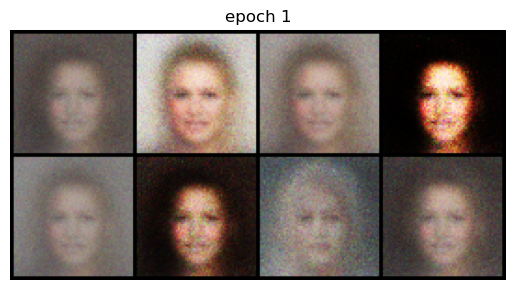

for epoch: 2/5... batch: 1... G-loss:4.727005958557129.... D-loss: 0.320473849773407
for epoch: 2/5... batch: 51... G-loss:2.6670432090759277.... D-loss: 0.19567175209522247
for epoch: 2/5... batch: 101... G-loss:3.2163796424865723.... D-loss: 0.3081246614456177
for epoch: 2/5... batch: 151... G-loss:4.70195198059082.... D-loss: 0.14696261286735535
for epoch: 2/5... batch: 201... G-loss:2.820056200027466.... D-loss: 0.22222258150577545
for epoch: 2/5... batch: 251... G-loss:2.7559499740600586.... D-loss: 0.21236373484134674
for epoch: 2/5... batch: 301... G-loss:3.740504264831543.... D-loss: 0.21657976508140564
for epoch: 2/5... batch: 351... G-loss:2.9711878299713135.... D-loss: 0.26590123772621155
for epoch: 2/5... batch: 401... G-loss:2.7193856239318848.... D-loss: 0.40129342675209045
for epoch: 2/5... batch: 451... G-loss:3.1017379760742188.... D-loss: 0.2952030897140503
for epoch: 2/5... batch: 501... G-loss:2.8969626426696777.... D-loss: 0.4732590317726135
for epoch: 2/5... batch

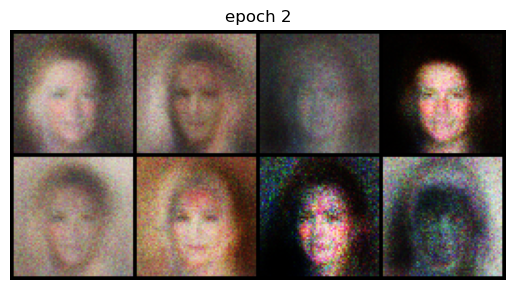

for epoch: 3/5... batch: 1... G-loss:3.071866989135742.... D-loss: 0.35375818610191345
for epoch: 3/5... batch: 51... G-loss:1.098961353302002.... D-loss: 0.454146146774292
for epoch: 3/5... batch: 101... G-loss:2.888850212097168.... D-loss: 0.26037001609802246
for epoch: 3/5... batch: 151... G-loss:2.7900567054748535.... D-loss: 0.3401799499988556
for epoch: 3/5... batch: 201... G-loss:2.8379948139190674.... D-loss: 0.23859760165214539
for epoch: 3/5... batch: 251... G-loss:2.322427749633789.... D-loss: 0.2919078469276428
for epoch: 3/5... batch: 301... G-loss:2.75040340423584.... D-loss: 0.30838268995285034


In [ ]:
train(generator, discriminator, dataloader, epochs=5)